ˆ
𝛉 = (X⊺X)−1X⊺y

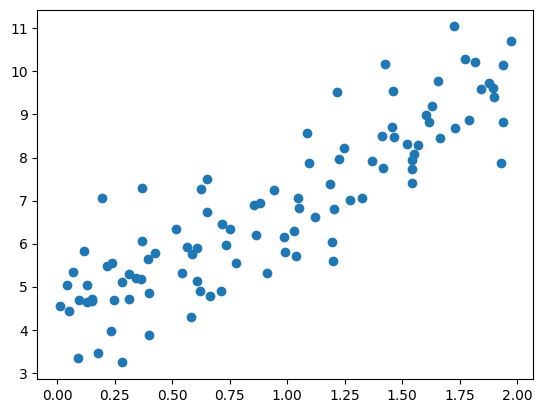

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
m=100
X = 2 * np.random.rand(m,1)
Y= 4+3*X + np.random.randn(m,1)
plt.scatter(X,Y)
plt.show()

In [2]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ Y
print(theta_best)

[[4.21509616]
 [2.77011339]]


here the real value is 4 and 3 it close enough but the gaussian noise made it impossible to know the exact value

In [ ]:
X_new = np.array([[0],[2]])
X_new_b = add_dummy_feature(X_new)
y_predict = X_new_b @ theta_best
y_predict

array([[4.21509616],
       [9.75532293]])

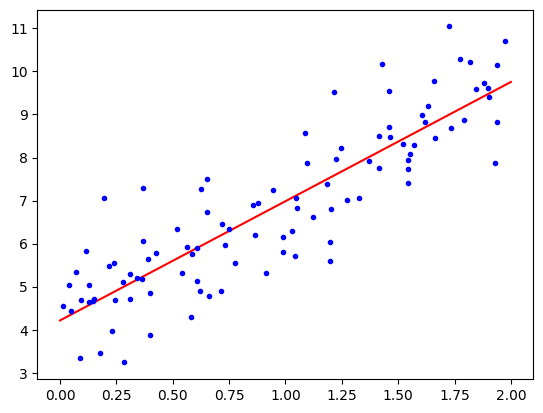

In [4]:

plt.plot(X_new, y_predict, "r-", label="Predictions")
plt.plot(X, Y, "b.")
plt.show()

In [5]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X,Y)
lin_reg.intercept_,lin_reg.coef_

(array([4.21509616]), array([[2.77011339]]))

In [6]:
lin_reg.predict(X_new)

array([[4.21509616],
       [9.75532293]])

coef does not include the bias

In [7]:
np.linalg.pinv(X_b) @ Y

array([[4.21509616],
       [2.77011339]])

the pseudoinverse use SVD that handle the expection very good ,the method normal need X.t @ X to be invertible

and also in complexity svd is about O(n**2) but the normal method need to inverse the matrix that is go between O(n**2,4) and O(n**3)

In [8]:
eta = 0.1
n_epochs = 1000
m = len(X_b)

np.random.seed(42)
theta = np.random.randn(2,1)
for epoch in range(n_epochs):
    gradients = 2/m * X_b.T @ (X_b @ theta-Y)
    theta-=eta * gradients

theta

array([[4.21509616],
       [2.77011339]])

In [9]:
n_epochs = 50
t0,t1 = 5,50

def learning_schedule(t):
    return t0/(t+t1)

np.random.seed(42)
theta = np.random.randn(2,1)

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        yi = Y[random_index:random_index+1]
        gradients = 2 * xi.T @ (xi @ theta-yi)
        eta = learning_schedule(m*epoch + iteration)
        theta -= eta * gradients
theta


array([[4.21076011],
       [2.74856079]])

In [10]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(tol=1e-5,eta0=0.01,penalty=None,max_iter=1000,n_iter_no_change=100)
sgd_reg.fit(X_b,Y.ravel())

sgd_reg.intercept_ , sgd_reg.coef_

(array([2.10740242]), array([2.10740242, 2.77002913]))

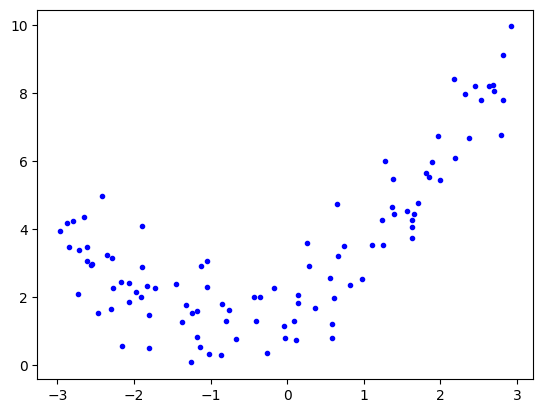

In [11]:
np.random.seed(42)
m=100
X = 6*np.random.rand(m,1) -3
Y = 0.5* X**(2) + X + 2 + np.random.randn(m,1)
plt.plot(X,Y,"b.")
plt.show()

In [12]:
from sklearn.preprocessing import PolynomialFeatures

poly_features = PolynomialFeatures(degree=2,include_bias=False)
X_poly = poly_features.fit_transform(X)
X[0]

array([-0.75275929])

In [13]:
X_poly[0]

array([-0.75275929,  0.56664654])

In [14]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly,Y)
lin_reg.intercept_,lin_reg.coef_

(array([1.78134581]), array([[0.93366893, 0.56456263]]))

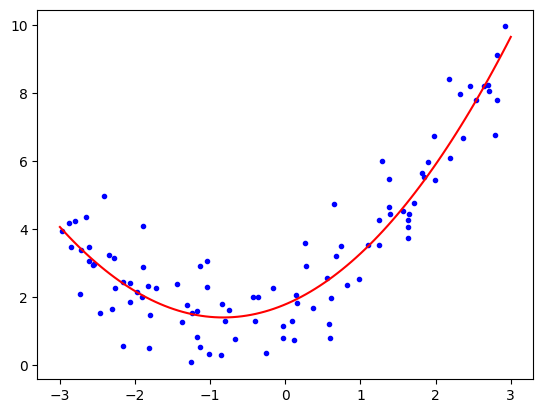

In [15]:
X_new = np.linspace(-3,3,100).reshape(100,1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.plot(X,Y,"b.")
plt.plot(X_new,y_new,"r-")
plt.show()

Learning Curves

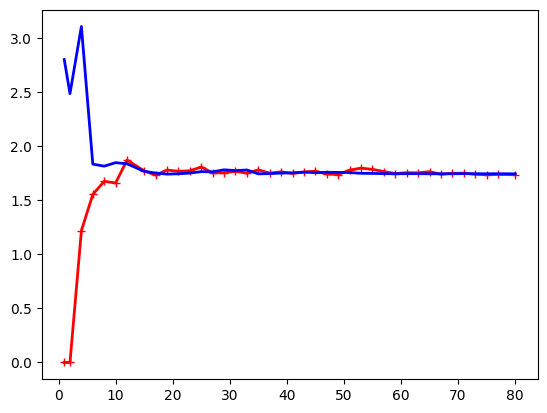

In [16]:
from sklearn.model_selection import learning_curve

train_sizes , train_scores ,valid_scores = learning_curve(LinearRegression(),X,Y,
                                        train_sizes = np.linspace(0.01,1.0,40),cv=5,scoring="neg_root_mean_squared_error")

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)
plt.plot(train_sizes,train_errors,"r-+",linewidth=2)
plt.plot(train_sizes,valid_errors,"b-",linewidth=2)
plt.show()

its clear that is an underfitting because the model fit the data when we have a small set but when we scale the model become harder to fit becaude the data is noisy and the data is not linear, and we have also that the curves meet and goes in two lines

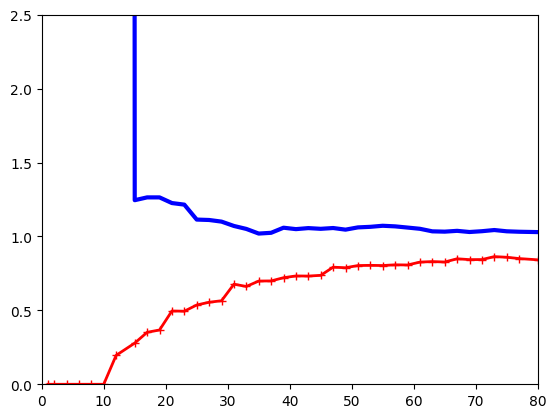

In [17]:
from sklearn.pipeline import make_pipeline

polynomial_regression = make_pipeline(PolynomialFeatures(degree=10,include_bias=False),
                                      LinearRegression())

train_sizes , train_scores , valid_scores = learning_curve(polynomial_regression,X,Y,train_sizes=np.linspace(0.01,1.0,40),
                                                           cv=5,scoring="neg_root_mean_squared_error")
train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.plot(train_sizes,train_errors,"r-+",linewidth=2)
plt.plot(train_sizes,valid_errors,"b-",linewidth=3)
plt.axis([0, 80, 0, 2.5])
plt.show()

we can see the curve of train is much lower but the gap is bigger than before and that may overfit

the bias/variance trade-off 

the generalization error expressed as the sum of bias , variance and irreductible error
bias is due to wrong assumption if its big we can say that the model overfit
variance model sensitivity to small variance , if its bigger then the model overfit
irreductible noise due to noise of ur data

Regularized models

this using closed form solution and the cholesky decomposer

In [18]:
from sklearn.linear_model import Ridge

ridge_reg = Ridge(alpha=0.1,solver="cholesky") #in sklearn +alpha/m * norm2
ridge_reg.fit(X,Y)
ridge_reg.predict([[1.5]])

array([4.82899748])

In [19]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(penalty="l2",alpha=0.1/m,tol=None,max_iter=1000,eta0=0.01,random_state=42)
sgd_reg.fit(X,Y.ravel())
sgd_reg.predict([[1.5]])

array([4.82830117])

the most important characterictic of lasso is the sparsity is selecting the most import important features and dropping out the least important

and for ridge the gradient slow down naturally and that help ridge go faster to the mini

In [20]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.1) #in sklearn +2*alpha*norm1
lasso.fit(X,Y)
lasso.predict([[1.5]])

array([4.77621741])

and for sgdregressor use the same but choose l1 for penalty

elastic net regression + r(2*alpha*norm1)+(1-r)alpha/m*norm2
it combines the sparsity and the smoothest of ridge

In [21]:
from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha=0.1,l1_ratio=0.5)
elastic_net.fit(X,Y)
elastic_net.predict([[1.5]])

array([4.78114505])

In [22]:
from copy import deepcopy
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)
X_train, y_train = X[: m // 2], y[: m // 2, 0]
X_valid, y_valid = X[m // 2 :], y[m // 2 :, 0]

preprocessing = make_pipeline(PolynomialFeatures(degree=90, include_bias=False),
                              StandardScaler())
X_train_prep = preprocessing.fit_transform(X_train)
X_valid_prep = preprocessing.transform(X_valid)
sgd_reg = SGDRegressor(penalty=None, eta0=0.002, random_state=42)
n_epochs = 500
best_valid_rmse = float('inf')
train_errors, val_errors = [], []

for epoch in range(n_epochs):
    sgd_reg.partial_fit(X_train_prep, y_train)
    y_valid_predict = sgd_reg.predict(X_valid_prep)
    val_error = root_mean_squared_error(y_valid, y_valid_predict)
    if val_error < best_valid_rmse:
        best_valid_rmse = val_error
        best_model = deepcopy(sgd_reg)  # we have that base.clone only store hyperparameters and deepcopy store also teta

    
    y_train_predict = sgd_reg.predict(X_train_prep)
    train_error = root_mean_squared_error(y_train, y_train_predict)
    val_errors.append(val_error)
    train_errors.append(train_error)

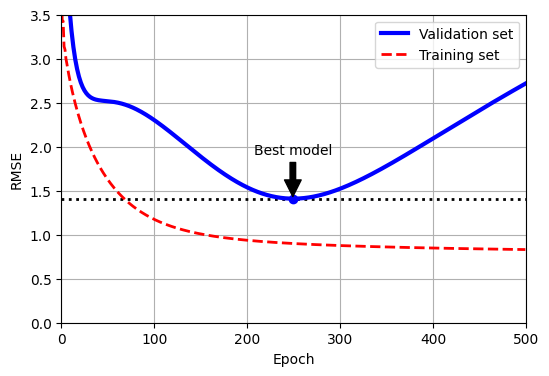

In [23]:

best_epoch = np.argmin(val_errors)
plt.figure(figsize=(6, 4))
plt.annotate('Best model',
             xy=(best_epoch, best_valid_rmse),
             xytext=(best_epoch, best_valid_rmse + 0.5),
             ha="center",
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.plot([0, n_epochs], [best_valid_rmse, best_valid_rmse], "k:", linewidth=2)
plt.plot(val_errors, "b-", linewidth=3, label="Validation set")
plt.plot(best_epoch, best_valid_rmse, "bo")
plt.plot(train_errors, "r--", linewidth=2, label="Training set")
plt.legend(loc="upper right")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.axis([0, n_epochs, 0, 3.5])
plt.grid()
plt.show()